In [16]:
import random
random.seed(42)

import torch

import numpy as np
import pyomo.environ as pyo
import pandas as pd
import matplotlib.pyplot as plt

from pyomo.environ import *
from utils import generate_simple_synthetic_data, const_embed, load_case_study_data
from trainer import Trainer

np.random.seed(43)

In [18]:
def generate_simple_synthetic_data(n_samples=1000, seed=42):
    np.random.seed(seed)

    # Contextual features
    x1 = np.random.uniform(0, 1, size=n_samples)   # e.g., income level
    x2 = np.random.uniform(0, 1, size=n_samples)   # e.g., brand loyalty

    # Price feature (bounded between realistic min and max)
    price = np.random.uniform(10, 30, size=n_samples)

    # Demand decay using sigmoid centered at mean price 17
    k = 0.35
    sigmoid = 1 / (1 + np.exp(k * (price - 17)))
    valid_price_mask = (price >= 10) & (price <= 30)
    base_demand = (5 * x1 + 3 * x2) * sigmoid

    true_mean = np.where(valid_price_mask, base_demand, 0)

    # Bell-shaped variability (highest near price 17)
    std_peak = 1.0
    std_min = 0.2
    width = 5

    base_std = std_min + (std_peak - std_min) * np.exp(-((price - 17)**2) / (2 * width**2))
    true_std = np.where(valid_price_mask, base_std, 0)

    # Sample demand, clip, round
    y = np.random.normal(loc=true_mean, scale=true_std)
    y = np.maximum(0, y)
    #y = np.round(y).astype(int)

    # Package
    X = pd.DataFrame({'x1': x1, 'x2': x2, 'price': price})
    y = pd.Series(y, name='y')

    return X, y, true_mean, true_std

In [28]:
X, y, true_mean, true_std = generate_simple_synthetic_data(n_samples=1000)

print(X.head())
print(y.head())


             x1            x2          price
0  0.3745401188  0.1851329288  15.2341136747
1  0.9507143064  0.5419009474  14.9395759814
2  0.7319939418  0.8729458359  28.1250916104
3  0.5986584842  0.7322248864  14.9909239970
4  0.1560186404  0.8065611479  15.4389945226
0    2.5863913530
1    4.8691830409
2    0.3080575466
3    2.1903196942
4    3.1922085443
Name: y, dtype: float64


x1       0.3058376265
x2       0.1573534546
price   -0.7485244188
Name: y, dtype: float64


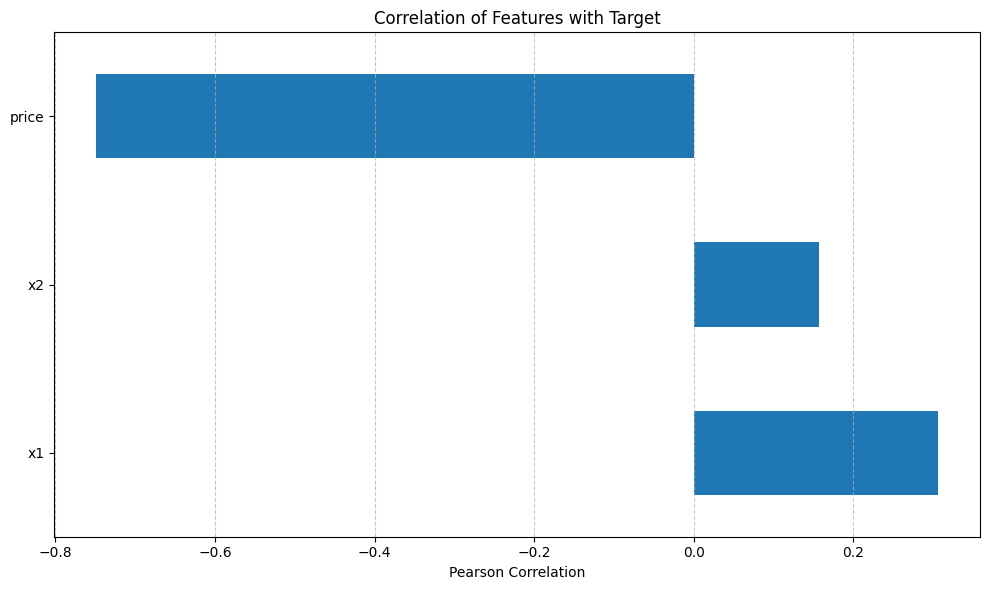

In [29]:
df = pd.concat([X, y], axis=1)

# Compute correlations of all columns with y
correlations = df.corr()['y'].drop('y')  # Drop self-correlation

# Display the correlations sorted by magnitude
print(correlations.sort_values(ascending=False))

# Plot
plt.figure(figsize=(10, 6))
correlations.plot(kind='barh')
plt.title('Correlation of Features with Target')
plt.xlabel('Pearson Correlation')
plt.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

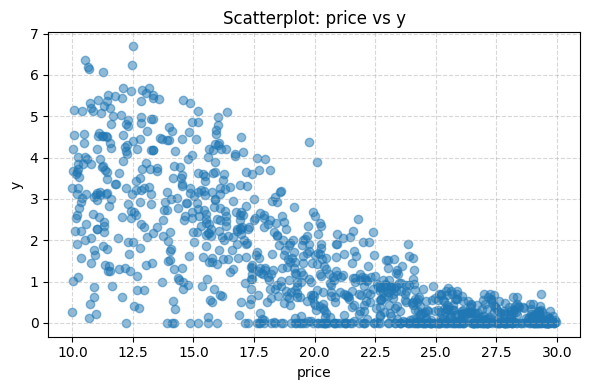

In [167]:
feature = 'price'
plt.figure(figsize=(6, 4))
plt.scatter(X[feature], y, alpha=0.5)
plt.xlabel(feature)
plt.ylabel('y')
plt.title(f'Scatterplot: {feature} vs y')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [168]:
X['price'].max()

np.float64(29.956417113639564)

In [14]:
1e-4

0.0001

In [ ]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

'''model_config = {
    'hidden_layers': 1,
    'hidden_size': 5,
    'drop': 0.2
    }

training_config = {
    'lr': 0.01,
    'wd': 0.0001,
    'batchsize': 64,
    'iters': 500,
    'patience': 20
    }'''

config = {
    # Model config
    'hidden_layers': 0,
    'hidden_size': 50,
    'drop': 0.05,

    # Training config
    'lr': 0.0001,
    'wd': 0,
    'batchsize': 64,
    'iters': 5000,
    'patience': 100
}

n_preds = 1

trainer = Trainer(X, y, config, n_preds=n_preds, device=device)
trainer.create_data_partitions(val_size=0.2, test_size=0.2, random_state=42)

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

trainer.train()

trainer.test()

X_train shape:  (12263, 32)
X_val shape:  (720, 32)
X_test shape:  (744, 32)
Validation loss improved from inf to 8.4115 in epoch 1. Saving model...
Epoch 1/5000 - Train Loss: 12.3464, Val Loss: 8.4115
Validation loss improved from 8.4115 to 7.4380 in epoch 2. Saving model...
Validation loss improved from 7.4380 to 7.0990 in epoch 3. Saving model...
Validation loss improved from 7.0990 to 6.9411 in epoch 4. Saving model...
Validation loss improved from 6.9411 to 6.8525 in epoch 5. Saving model...
Validation loss improved from 6.8525 to 6.7936 in epoch 6. Saving model...
Validation loss improved from 6.7936 to 6.7487 in epoch 7. Saving model...
Validation loss improved from 6.7487 to 6.7117 in epoch 8. Saving model...
Validation loss improved from 6.7117 to 6.6797 in epoch 9. Saving model...
Validation loss improved from 6.6797 to 6.6533 in epoch 10. Saving model...
Validation loss improved from 6.6533 to 6.6128 in epoch 11. Saving model...
Epoch 11/5000 - Train Loss: 7.0333, Val Loss: 

In [23]:
trainer.model

distModel(
  (input_layer): Linear(in_features=32, out_features=50, bias=True)
  (hidden_layers): ModuleList()
  (output_mean_layer): Linear(in_features=50, out_features=1, bias=True)
  (output_sd_layer): Linear(in_features=50, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.05, inplace=False)
)

In [48]:
#trainer.predict(X=trainer.X_test)

In [24]:
trainer.evaluate_gaussian_nll()
trainer.evaluate_standardized_residuals()

Baseline Gaussian NLL Loss: 6.5904
Model Gaussian NLL Loss: 6.4238
KS test against N(0,1): statistic = 0.1543, p-value = 0.0000
⚠️ The standardized residuals significantly differ from a standard normal distribution — model variance estimates may be miscalibrated.
Saved: residual_diagnostics\z_histogram.png
Saved: residual_diagnostics\z_qqplot.png


(np.float64(0.15427864583985265), np.float64(1.9752026675150583e-15))

In [162]:
'''# Inputs
x = np.array([[-1.266313, -0.405118, 0.612491]])

# Extract weights from model
state_dict = trainer.model.state_dict()
w0 = state_dict['input_layer.weight'].cpu().numpy()
b0 = state_dict['input_layer.bias'].cpu().numpy()

w1 = state_dict['hidden_layers.0.weight'].cpu().numpy()
b1 = state_dict['hidden_layers.0.bias'].cpu().numpy()

w_mean = state_dict['output_mean_layer.weight'].cpu().numpy()
b_mean = state_dict['output_mean_layer.bias'].cpu().numpy()

w_sd = state_dict['output_sd_layer.weight'].cpu().numpy()
b_sd = state_dict['output_sd_layer.bias'].cpu().numpy()

# Manual forward pass
def relu(x): return np.maximum(0, x)

h0 = relu(x.dot(w0.T) + b0)
h1 = relu(h0.dot(w1.T) + b1)
mean = h1.dot(w_mean.T) + b_mean
sd = relu(h1.dot(w_sd.T) + b_sd)

print("Manual mean:", mean)
print("Manual std:", sd)'''

'# Inputs\nx = np.array([[-1.266313, -0.405118, 0.612491]])\n\n# Extract weights from model\nstate_dict = trainer.model.state_dict()\nw0 = state_dict[\'input_layer.weight\'].cpu().numpy()\nb0 = state_dict[\'input_layer.bias\'].cpu().numpy()\n\nw1 = state_dict[\'hidden_layers.0.weight\'].cpu().numpy()\nb1 = state_dict[\'hidden_layers.0.bias\'].cpu().numpy()\n\nw_mean = state_dict[\'output_mean_layer.weight\'].cpu().numpy()\nb_mean = state_dict[\'output_mean_layer.bias\'].cpu().numpy()\n\nw_sd = state_dict[\'output_sd_layer.weight\'].cpu().numpy()\nb_sd = state_dict[\'output_sd_layer.bias\'].cpu().numpy()\n\n# Manual forward pass\ndef relu(x): return np.maximum(0, x)\n\nh0 = relu(x.dot(w0.T) + b0)\nh1 = relu(h0.dot(w1.T) + b1)\nmean = h1.dot(w_mean.T) + b_mean\nsd = relu(h1.dot(w_sd.T) + b_sd)\n\nprint("Manual mean:", mean)\nprint("Manual std:", sd)'

In [25]:
cons = trainer.constraint_build()
cons.to_csv('constraints.csv')

In [26]:
cons = pd.read_csv('constraints.csv', index_col=0)
pd.set_option('display.precision', 10)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,...,node_40,node_41,node_42,node_43,node_44,node_45,node_46,node_47,node_48,node_49
0,-0.1697464900,0,0,-0.1411772400,-0.0378720600,0.118837730,-0.1234561900,0.052029118,-0.1151752600,-0.037941396,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.0280475470,0,1,-0.1257740700,-0.0766960750,0.110703185,0.0483061080,-0.090942150,0.0245812680,-0.134729010,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.1637017000,0,2,-0.1182339400,-0.0130834130,0.009061724,0.0392837970,-0.091917240,-0.1245371100,0.076989725,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-0.4346138800,0,3,-0.1411119800,-0.1641936700,-0.155120150,-0.3492538300,-0.240584220,-0.4549776300,-0.460149050,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-0.5315256000,0,4,0.0036250344,-0.3225432000,-0.335724830,-0.3119168600,-0.309916730,-0.3568399800,-0.455058200,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.1649267400,0,5,0.1381966800,0.1295771000,0.085977465,-0.0441043300,0.130191420,-0.0350809880,0.168276470,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,-0.1600498100,0,6,0.1381602100,-0.1162149400,0.074947880,-0.0809920600,0.035551682,-0.1593950500,-0.081413740,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,-0.4815293600,0,7,-0.2702862300,-0.4768807000,-0.236778360,-0.4929220700,-0.537358340,-0.5471617000,-0.534377400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,-0.0500901530,0,8,-0.1098917050,-0.0858556500,-0.337872240,-0.0814539640,-0.041812476,0.0072595887,-0.156590030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.1568523500,0,9,-0.1710302800,0.0977193600,-0.020606205,-0.0135252330,0.161608140,0.0065149070,-0.078198730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
n_sc =  300
#contextual_var = trainer.X_test
contextual_var = trainer.X_test.iloc[[1]]
contextual_var.reset_index(drop=True, inplace=True)
contextual_var

,price,temperature,holiday,weekend,temperature_mean24,temperature_min24,temperature_max24,hour_sin,hour_cos,dweek_sin,...,temperature_24lag,temperature_48lag,temperature_72lag,temperature_96lag,temperature_120lag,temperature_144lag,temperature_168lag,demand_daymean_24lag,demand_daymin_24lag,demand_daymax_24lag
0,8.71,9.9,0,1,12.3083333333,8.7,15.8,0.2697967712,0.9629172873,-0.8660254038,...,11.2,12.4,10.5,13.6,8.1,8.3,8.4,1450.2184132737,1000.3940069364,2001.3597419355


In [273]:
contextual_var.columns.sort_values()

Index(['price', 'x1', 'x2'], dtype='object')

In [295]:
row = pd.DataFrame([{
    'x1': -1.266313,
    'x2': -0.405118,
    'price': 30.0
}])

def preict_one_row(row):
    # Predict
    mean_pred, sd_pred = trainer.predict(row, unscale=True)
    print("Mean prediction:", mean_pred)
    print("Standard deviation prediction:", sd_pred)

preict_one_row(row)

Mean prediction: [[0.13684099]]
Standard deviation prediction: [[2.72496209]]


In [275]:
model = pyo.ConcreteModel()
    
model.N = pyo.RangeSet(0,n_preds-1)
model.W = pyo.RangeSet(1,n_sc) # scenarios

pi = [1/n_sc for i in range(n_sc)]

model.var_ind = pyo.Set(initialize=contextual_var.columns.sort_values())

model.x = pyo.Var(model.var_ind, model.N) # price

model.y = pyo.Var(pyo.Any, dense=False, domain=pyo.Reals)

model.rent = pyo.Var(model.W, within=pyo.Reals) # rentabilidad per scenario

#definition of the objective function
def obj_expression(model):
    return sum(pi[w-1] * model.rent[w] for w in model.W)
model.OBJ = pyo.Objective(rule=obj_expression, sense=pyo.maximize)

#definition of the constraints

def rent_expression(model, w):
    return model.rent[w] == sum(model.y['demand', n, w]*model.x['price',n] for n in model.N)
model.rent_expression = pyo.Constraint(model.W, rule=rent_expression)

'''# fix price
def price_expression(model, n):
    return model.x['price', n] == 10
model.price_expression = pyo.Constraint(model.N, rule=price_expression)'''

#constraint for fixing contextual information
def const9_rule(model,x_ind,n):
    if x_ind=='price':
        return pyo.Constraint.Skip
    else:
        return model.x[x_ind,n] == contextual_var.loc[n,x_ind]
model.const9 = pyo.Constraint(model.var_ind, model.N, rule=const9_rule)


P_max = 30
# max price constraint for each price
def max_price_expression(model, n):
    return model.x['price', n] <= P_max

model.max_price_expression = pyo.Constraint(model.N, rule=max_price_expression)

def min_price_expression(model, n):
    return model.x['price', n] >= 0
model.min_price_expression = pyo.Constraint(model.N, rule=min_price_expression)


In [276]:
const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand', n_scenarios=n_sc)

In [277]:
opt = pyo.SolverFactory('gurobi_direct')
opt.options['threads'] = 0
opt.options['NonConvex'] = 2
results = opt.solve(model, tee=True)

Set parameter OutputFlag to value 1
Set parameter Threads to value 0
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13500, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Non-default parameters:
NonConvex  2

Optimize a model with 256 rows, 305 columns and 956 nonzeros
Model fingerprint: 0x03915615
Model has 100 quadratic constraints
Variable types: 255 continuous, 50 integer (50 binary)
Coefficient statistics:
  Matrix range     [3e-03, 1e+03]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [1e-02, 1e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e-02, 1e+03]
Presolve removed 115 rows and 176 columns
Presolve time: 0.00s
Presolved: 342 rows, 231 columns, 1022 nonzeros
Presolved model has 100 bilinear constraint(s)

Solving non-convex MIQCP

Variable types: 218 

In [278]:
for c in model.component_objects(Constraint, active=True):
    print(f"Constraint component: {c.name}")
    for index in c:
        print(f"  {index}: {c[index].expr}")

Constraint component: rent_expression
  1: rent[1]  ==  y[demand,0,1]*x[price,0]
  2: rent[2]  ==  y[demand,0,2]*x[price,0]
  3: rent[3]  ==  y[demand,0,3]*x[price,0]
  4: rent[4]  ==  y[demand,0,4]*x[price,0]
  5: rent[5]  ==  y[demand,0,5]*x[price,0]
  6: rent[6]  ==  y[demand,0,6]*x[price,0]
  7: rent[7]  ==  y[demand,0,7]*x[price,0]
  8: rent[8]  ==  y[demand,0,8]*x[price,0]
  9: rent[9]  ==  y[demand,0,9]*x[price,0]
  10: rent[10]  ==  y[demand,0,10]*x[price,0]
  11: rent[11]  ==  y[demand,0,11]*x[price,0]
  12: rent[12]  ==  y[demand,0,12]*x[price,0]
  13: rent[13]  ==  y[demand,0,13]*x[price,0]
  14: rent[14]  ==  y[demand,0,14]*x[price,0]
  15: rent[15]  ==  y[demand,0,15]*x[price,0]
  16: rent[16]  ==  y[demand,0,16]*x[price,0]
  17: rent[17]  ==  y[demand,0,17]*x[price,0]
  18: rent[18]  ==  y[demand,0,18]*x[price,0]
  19: rent[19]  ==  y[demand,0,19]*x[price,0]
  20: rent[20]  ==  y[demand,0,20]*x[price,0]
  21: rent[21]  ==  y[demand,0,21]*x[price,0]
  22: rent[22]  ==  y[d

In [279]:
value(model.x['price', 0])

30.0

In [281]:
value(model.y['demand', 0, 1])

4.457937767547743

In [260]:
print(value(model.y['demand', 0, 'mean']))
print(value(model.y['demand', 0, 'sd']))

0.2266403243874446
1.6178296322501855


In [142]:
opt_profit = value(model.OBJ)
print(f"Optimal profit: {opt_profit}")

Optimal profit: 13.879221394392099


In [143]:
opt_price = value(model.x['price',0])
opt_mean = value(model.y['demand', 0,'mean'])
opt_sd = value(model.y['demand', 0,'sd'])

print(f"Optimal price: {opt_price}")
print(f"Optimal mean: {opt_mean}")
print(f"Optimal sd: {opt_sd}")

Optimal price: 10.0
Optimal mean: -0.031053547670377823
Optimal sd: 0.2714667772099779
